<a href="https://colab.research.google.com/github/peeyush211/ML-Lab/blob/main/Lab_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Lab 9**

**Aim - Perform Kmeans clustering vs Dbscan Clustering on sample dataset**

**Peeyush Agarwal 2427010184 AIM3130**

In [3]:
# Import libraries and load the Iris dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)

display(df.head())
print("Dataset shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())

# Standardize all four numerical features before clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Dataset shape: (150, 4)

Missing values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


In [4]:
# Apply K-Means with three clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

# Apply DBSCAN; -1 represents noise points
dbscan = DBSCAN(eps=0.7, min_samples=5)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

display(df.head(10))

print("K-Means cluster sizes:")
print(df['KMeans_Cluster'].value_counts().sort_index())

print("\nDBSCAN cluster sizes (-1 = noise):")
print(df['DBSCAN_Cluster'].value_counts().sort_index())

n_clusters = len(set(dbscan.labels_) - {-1})
n_noise = np.sum(dbscan.labels_ == -1)

print("\nNumber of DBSCAN clusters:", n_clusters)
print("Number of noise points:", n_noise)

# Compare average feature values within each cluster
print("\nK-Means cluster averages:")
display(df.groupby('KMeans_Cluster')[iris.feature_names].mean())

print("\nDBSCAN cluster averages (-1 = noise):")
display(df.groupby('DBSCAN_Cluster')[iris.feature_names].mean())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),KMeans_Cluster,DBSCAN_Cluster
0,5.1,3.5,1.4,0.2,1,0
1,4.9,3.0,1.4,0.2,1,0
2,4.7,3.2,1.3,0.2,1,0
3,4.6,3.1,1.5,0.2,1,0
4,5.0,3.6,1.4,0.2,1,0
5,5.4,3.9,1.7,0.4,1,0
6,4.6,3.4,1.4,0.3,1,0
7,5.0,3.4,1.5,0.2,1,0
8,4.4,2.9,1.4,0.2,1,0
9,4.9,3.1,1.5,0.1,1,0


K-Means cluster sizes:
KMeans_Cluster
0    53
1    50
2    47
Name: count, dtype: int64

DBSCAN cluster sizes (-1 = noise):
DBSCAN_Cluster
-1     6
 0    48
 1    96
Name: count, dtype: int64

Number of DBSCAN clusters: 2
Number of noise points: 6

K-Means cluster averages:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
KMeans_Cluster,,,,
0,5.801887,2.673585,4.369811,1.413208
1,5.006000,3.428000,1.462000,0.246000
2,6.780851,3.095745,5.510638,1.972340



DBSCAN cluster averages (-1 = noise):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
DBSCAN_Cluster,,,,
-1,6.316667,3.400000,4.416667,1.516667
0,5.002083,3.431250,1.464583,0.241667
1,6.234375,2.848958,4.863542,1.658333


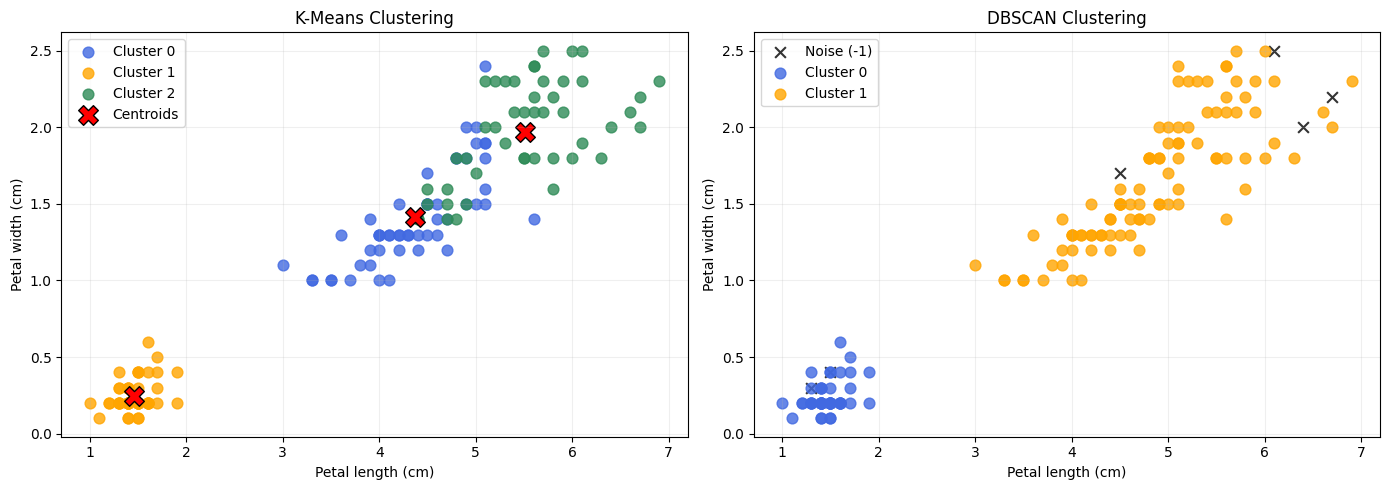

In [5]:
# Plot clusters using the original petal measurements
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['royalblue', 'orange', 'seagreen', 'purple', 'brown']

for ax, column, title in zip(
    axes,
    ['KMeans_Cluster', 'DBSCAN_Cluster'],
    ['K-Means Clustering', 'DBSCAN Clustering']
):
    labels = sorted(df[column].unique())

    for label in labels:
        points = df[df[column] == label]

        ax.scatter(
            points['petal length (cm)'],
            points['petal width (cm)'],
            color='black' if label == -1 else colors[label % len(colors)],
            marker='x' if label == -1 else 'o',
            label='Noise (-1)' if label == -1 else f'Cluster {label}',
            s=60,
            alpha=0.8
        )

    ax.set_title(title)
    ax.set_xlabel('Petal length (cm)')
    ax.set_ylabel('Petal width (cm)')
    ax.legend()
    ax.grid(alpha=0.2)

# Convert K-Means centers back to the original measurement scale
centers = scaler.inverse_transform(kmeans.cluster_centers_)

axes[0].scatter(
    centers[:, 2],
    centers[:, 3],
    color='red',
    marker='X',
    s=200,
    edgecolors='black',
    label='Centroids'
)
axes[0].legend()

plt.tight_layout()
plt.show()